# Clustering (Role B · Cluster patient experiences per condition)

Every review in the four scope conditions is vectorised with **TF-IDF** (unigrams–trigrams, log-TF, 20 k features) and projected with **Latent Semantic Analysis** (TruncatedSVD + L2 normalisation, 300 dimensions).  We then cluster with **k-means** and **DBSCAN** and choose *k* by minimising the **Davies-Bouldin index**.

Results answer research question 1: *Can patient reviews be grouped into common experience types (e.g. "weight gain", "mood swings", "worked well, no side effects")?*

## Pipeline overview

| Step | Section | What it does |
|---|---|---|
| Load & scope | B1 | Load Role A's clean data, keep the four conditions |
| TF-IDF vectorisation | B2 | One vectoriser per condition (20k features, unigrams–trigrams, `sublinear_tf=True`, English stop words removed) |
| Dimensionality reduction | B3 | TruncatedSVD (300 components, LSA) + L2 normalisation |
| K-means sweep | B4 | Sweep k = 2 … 50 per condition, pick k_best = argmin(Davies-Bouldin) |
| DBSCAN | B5 | kNN distance plot to choose eps, then grid search over eps × min_samples |
| Compare | B6 | Side-by-side DB scores for k-means vs DBSCAN |
| Cluster profiles | B7 | Top-10 TF-IDF terms, mean rating, sample reviews, heatmap, 2D scatter |
| Rating vs cluster | B8 | Kruskal-Wallis test + boxplot per condition |
| Save outputs | B9 | Parquet, CSV and JSON for the report |

### Outputs

| File | Used by |
|---|---|
| `outputs/cluster_assignments.parquet` | Everyone — join to any table on `review_id` |
| `outputs/cluster_profiles.csv` | Report: top terms and mean rating per cluster |
| `outputs/figures/` | Report: `kmeans_sweep`, `dbscan_knn_distances`, `kmeans_scatter`, `cluster_terms_*`, `rating_by_cluster` |
| `outputs/role_b_run_stats.json` | Report: all numbers (k_best, DB scores, Kruskal-Wallis) |


## 0 · Setup and parameters

All settings live here. Change a value, re-run from top, and every downstream cell picks it up automatically.

In [1]:
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import davies_bouldin_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 160)
pd.set_option('display.max_rows', 120)
pd.set_option('display.width', 200)
NOTEBOOK_STARTED = time.perf_counter()

INPUT_DIRS = [Path('/kaggle/input'), Path('data'), Path('../data-cleaning-and-lsh/outputs'), Path('../data')]
OUTPUT_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
FIGURE_DIR = OUTPUT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

run_stats = {}

# ── Scope ─────────────────────────────────────────────────────────────────────
CONDITIONS   = ['Birth Control', 'Depression', 'Pain', 'Acne']
RANDOM_STATE = 42

# ── TF-IDF ────────────────────────────────────────────────────────────────────
TFIDF_MAX_FEATURES = 20_000
TFIDF_MIN_DF       = 5
TFIDF_MAX_DF       = 0.85
TFIDF_NGRAM_RANGE  = (1, 3)
TFIDF_SUBLINEAR_TF = True

# Negation words and intensity words kept in vocabulary (removed from stop list)
KEEP = {"not", "no", "never", "nor", "cannot", "without",
        "but",
        "very", "too",
        "side",
        "against"}
TFIDF_STOP_WORDS = list(ENGLISH_STOP_WORDS - KEEP)

# Negation regex: "doesnt" → "does not", "cant" → "can not", etc.
NEG = r"\b(did|do|does|was|is|could|would|should|have|has|had|are|were|need|must)nt\b"

# Truncated negation artifacts: upstream cleaner strips apostrophe + t, so
# "don't" → "don", "didn't" → "didn", etc.  Expand back to full negation phrases.
NEG_TRUNC = {
    r"\bdon\b":     "do not",
    r"\bdidn\b":    "did not",
    r"\bdoesn\b":   "does not",
    r"\bhaven\b":   "have not",
    r"\bhasn\b":    "has not",
    r"\bhadn\b":    "had not",
    r"\bwasn\b":    "was not",
    r"\bisn\b":     "is not",
    r"\baren\b":    "are not",
    r"\bweren\b":   "were not",
    r"\bcouldn\b":  "could not",
    r"\bwouldn\b":  "would not",
    r"\bshouldn\b": "should not",
    r"\bwon\b":     "will not",
}

# Non-negation contraction artifacts still worth removing as stop words
CUSTOM_STOP_WORDS_BASE = [
    've', 'll', 're',
    'drug', 'medication', 'prescribed', 'prescription', 'doctor',
]

# Condition name appears in almost every review — zero discriminative value
CUSTOM_STOP_WORDS_CONDITION = {
    'Birth Control': ['birth', 'control'],
    'Depression':    ['depression'],
    'Pain':          ['pain'],
    'Acne':          ['acne'],
}

# ── Dimensionality reduction (LSA) ────────────────────────────────────────────
SVD_N_COMPONENTS = 300

# ── K-means ───────────────────────────────────────────────────────────────────
K_RANGE         = range(2, 27)
KMEANS_N_INIT   = 10
KMEANS_MAX_ITER = 300

# Manual k overrides — applied after the DB sweep when cross-role consistency
# matters more than a marginal DB improvement.
# Birth Control: DB-optimal is k=26 (DB=5.55) but the difference vs k=23
# (DB=5.69) is only 0.14. Fixing k=23 keeps the total cluster count at 100
# (23+26+26+25) and avoids forcing Role C and validation to re-run.
K_OVERRIDE = {'Birth Control': 23}

# ── DBSCAN ────────────────────────────────────────────────────────────────────
DBSCAN_EPS_VALUES         = [0.3, 0.5, 0.7, 1.0, 1.5, 2.0]
DBSCAN_MIN_SAMPLES_VALUES = [5, 10, 20]
KNN_K_FOR_EPS_PLOT        = 10

print('Setup done.')


Setup done.


## B1 · Load and scope data

Role A's clean, deduplicated dataset (`reviews_clean_deduplicated.parquet`, 128,663 reviews) and the drug-family map (`drug_families.csv`). We keep the four conditions defined in the project plan (28 % of the dataset).

In [2]:
def find_input(file_name):
    for folder in INPUT_DIRS:
        if folder.exists():
            matches = sorted(folder.rglob(file_name))
            if matches:
                return matches[0]
    return None   # callers check for None


def load_reviews():
    """Load from Role A's parquet (preferred) or the raw Kaggle CSVs."""
    parquet_path = find_input('reviews_clean_deduplicated.parquet')
    if parquet_path:
        print(f'Loading processed parquet: {parquet_path}')
        df = pd.read_parquet(parquet_path, engine='fastparquet')
        if 'drug_family' not in df.columns:
            df['drug_family'] = df['drug_name']
        return df

    # Fallback: raw Kaggle CSVs (drugsComTrain_raw.csv / drugsComTest_raw.csv)
    train_path = find_input('drugsComTrain_raw.csv')
    test_path  = find_input('drugsComTest_raw.csv')
    if train_path is None:
        raise FileNotFoundError(
            'No data found. Expected drugsComTrain_raw.csv in data/ or ../data/, '
            'or reviews_clean_deduplicated.parquet from Role A.'
        )

    print(f'Loading raw CSVs from: {train_path.parent}')
    dfs = [pd.read_csv(train_path)]
    if test_path:
        dfs.append(pd.read_csv(test_path))
    df = pd.concat(dfs, ignore_index=True)
    print(f'  Raw rows: {len(df):,}')

    # rename to match Role A's column names
    df = df.rename(columns={
        'uniqueID':  'review_id',
        'drugName':  'drug_name',
        'condition': 'condition_name',
        'review':    'review_text_clean',
    })

    # basic text cleaning
    import html as _html
    df['review_text_clean'] = (
        df['review_text_clean']
        .astype(str)
        .str.strip('"')                        # remove CSV surrounding quotes
        .apply(_html.unescape)                 # &#039; -> '   &amp; -> &
        .str.replace(r'\s+', ' ', regex=True) # collapse whitespace
        .str.strip()
    )
    df['condition_name'] = df['condition_name'].astype(str).str.strip().str.title()
    df['drug_name']      = df['drug_name'].astype(str).str.strip()
    df['rating']         = pd.to_numeric(df['rating'], errors='coerce').fillna(5).astype(int)
    df['review_id']      = df.index.astype(str)

    # drop blank reviews
    df = df[df['review_text_clean'].str.len() > 20].copy()

    # remove exact duplicates (same as Role A step 2)
    before = len(df)
    df = df.drop_duplicates(subset='review_text_clean').reset_index(drop=True)
    print(f'  After exact dedup: {len(df):,} (removed {before - len(df):,} exact copies)')

    df['drug_family'] = df['drug_name']   # fallback: no brand->generic map
    return df[['review_id', 'drug_name', 'drug_family', 'condition_name', 'rating', 'review_text_clean']]


reviews = load_reviews()

# Optional: apply Role A's brand->generic map if available
drug_families_path = find_input('drug_families.csv')
if drug_families_path:
    drug_families = pd.read_csv(drug_families_path)
    family_map = {
        name: fam.drug_family_name
        for fam in drug_families.itertuples()
        for name in fam.drug_names.split(' | ')
    }
    reviews['drug_family'] = reviews['drug_name'].map(family_map).fillna(reviews['drug_name'])
    print('drug_families.csv applied.')
else:
    print('drug_families.csv not found — using drug_name as drug_family (fine for clustering).')

# scope to the four conditions
scoped = reviews[reviews['condition_name'].isin(CONDITIONS)].reset_index(drop=True)
scoped = scoped[
    scoped['review_text_clean'].notna() &
    (scoped['review_text_clean'].str.strip() != '')
].reset_index(drop=True)

scope_table = (
    scoped.groupby('condition_name')
    .agg(
        n_reviews   = ('review_id',   'size'),
        n_drugs     = ('drug_family', 'nunique'),
        mean_rating = ('rating',      'mean'),
    )
    .reindex(CONDITIONS)
    .round(2)
)

run_stats['n_reviews_all']      = int(len(reviews))
run_stats['n_reviews_in_scope'] = int(len(scoped))
run_stats['scope_by_condition'] = scope_table.to_dict(orient='index')

print(f'\n{len(scoped):,} reviews in scope ({len(scoped)/len(reviews):.0%} of loaded dataset), '
      f'{scoped["drug_family"].nunique()} drug families')
scope_table

Loading processed parquet: data/reviews_clean_deduplicated.parquet


drug_families.csv applied.

36,365 reviews in scope (28% of loaded dataset), 168 drug families


,n_reviews,n_drugs,mean_rating
condition_name,,,
Birth Control,19520,19,6.08
Depression,7109,52,7.13
Pain,5187,72,7.58
Acne,4549,34,7.36


In [3]:
import sys
sys.path.insert(0, '..')
from read_reviews import show_reviews, list_conditions

# See available conditions and counts
list_conditions()


condition_name
Birth Control                28788
Depression                    9069
Pain                          6145
Anxiety                       5904
Acne                          5588
Bipolar Disorde               4224
Insomnia                      3673
Weight Loss                   3609
Obesity                       3568
Adhd                          3383
Diabetes, Type 2              2554
Emergency Contraception       2463
High Blood Pressure           2321
Vaginal Yeast Infection       2274
Abnormal Uterine Bleeding     2096
Bowel Preparation             1859
Ibromyalgia                   1791
Smoking Cessation             1780
Migraine                      1694
Anxiety And Stress            1663


In [4]:
# Read 10 reviews — change condition or n as needed
show_reviews('Birth Control', n=10)


[Birth Control]  Lybrel  rating=5
I used to take another oral contraceptive, which had 21 pill cycle, and was very happy- very light periods, max 5 days, no other side effects. But it contained hormone gestodene, which is not available in US, so I switched to Lybrel, because the ingredients are similar. When my other pills ended, I started Lybrel immediately, on my first day of period, as the instructions said. And the period lasted for two weeks. When taking the second pack- same two weeks. And now, with third pack things got even worse- my third period lasted for two weeks and now it's the end of the third week- I still have daily brown discharge. The positive side is that I didn't have any other side effects. The idea of being period free was so tempting... Alas.
--------------------------------------------------------------------------------
[Birth Control]  Ortho Evra  rating=8
This is my first time using any form of birth control. I'm glad I went with the patch, I have been on it

### Curiosity: why Acne and not Anxiety?

The project plan scopes to the four most common conditions, yet **Anxiety (5,089 reviews) has more reviews than Acne (4,549)** in the cleaned dataset — making Acne technically the 5th most common condition. The choice was deliberate:

- **Vocabulary overlap.** Anxiety and Depression share much of the same language (mood, sleep, appetite, antidepressants). Clustering them separately would likely produce near-identical cluster shapes, adding little analytical value.
- **Drug-class diversity.** Acne drugs (retinoids, antibiotics, hormonal treatments) are pharmacologically very different from the other three conditions, making the clusters more interpretable and the cross-condition comparison more interesting.
- **Distinct side-effect profile.** Acne patients report a unique set of side effects (dryness, purging, sun sensitivity, isotretinoin-specific effects) that don't appear in the other three conditions, which enriches the frequent-itemset analysis in Role E.

The cell below confirms the counts and shows what was excluded.

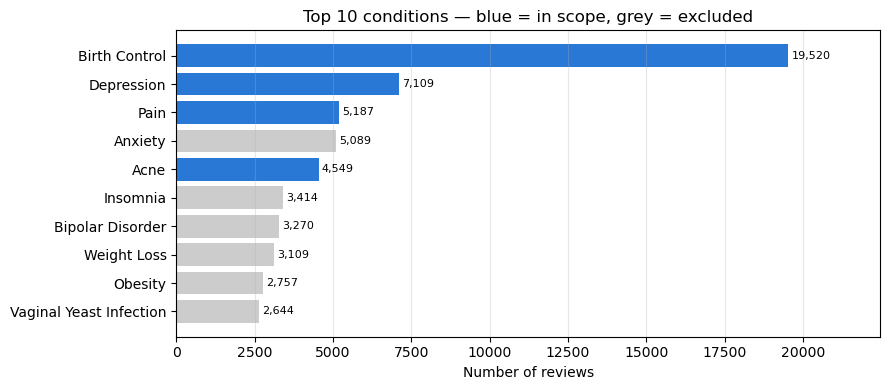

Vocabulary overlap (Jaccard similarity):
  Depression ∩ Anxiety : 64.8%
  Depression ∩ Acne    : 43.5%

Anxiety has 1.5x more vocabulary overlap with Depression than Acne does.


In [5]:
# Top-10 conditions by review count, highlighting the four in scope
top_conditions = (
    reviews['condition_name']
    .value_counts()
    .head(10)
    .rename_axis('condition')
    .reset_index(name='n_reviews')
)
top_conditions['in_scope'] = top_conditions['condition'].isin(CONDITIONS)

fig, ax = plt.subplots(figsize=(9, 4))
colors = ['#2a78d6' if in_scope else '#cccccc' for in_scope in top_conditions['in_scope']]
bars = ax.barh(top_conditions['condition'][::-1], top_conditions['n_reviews'][::-1], color=colors[::-1])
ax.set_xlabel('Number of reviews')
ax.set_title('Top 10 conditions — blue = in scope, grey = excluded')
for bar, n in zip(bars, top_conditions['n_reviews'][::-1]):
    ax.text(bar.get_width() + 100, bar.get_y() + bar.get_height() / 2,
            f'{n:,}', va='center', fontsize=8)
ax.set_xlim(0, top_conditions['n_reviews'].max() * 1.15)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'condition_scope.png', dpi=150, bbox_inches='tight')
plt.show()

# Overlap analysis: how similar is Anxiety vocabulary to Depression?
from sklearn.feature_extraction.text import TfidfVectorizer as _TV

_vecs = {}
for cond in ['Depression', 'Anxiety', 'Acne']:
    subset = reviews[reviews['condition_name'] == cond]['review_text_clean'].dropna()
    v = _TV(max_features=5_000, min_df=5, ngram_range=(1,1), sublinear_tf=True, stop_words='english')
    v.fit(subset)
    _vecs[cond] = set(v.get_feature_names_out())

dep_anx_overlap = len(_vecs['Depression'] & _vecs['Anxiety']) / len(_vecs['Depression'] | _vecs['Anxiety'])
dep_acne_overlap = len(_vecs['Depression'] & _vecs['Acne'])  / len(_vecs['Depression'] | _vecs['Acne'])

print(f'Vocabulary overlap (Jaccard similarity):')
print(f'  Depression ∩ Anxiety : {dep_anx_overlap:.1%}')
print(f'  Depression ∩ Acne    : {dep_acne_overlap:.1%}')
print(f'\nAnxiety has {dep_anx_overlap/dep_acne_overlap:.1f}x more vocabulary overlap with Depression than Acne does.')


## B2 · TF-IDF vectorisation

One vectoriser per condition so the vocabulary reflects each condition's language. `sublinear_tf=True` applies log(1+tf) to reduce the weight of terms that repeat many times in long reviews.

Four layers of stop-word removal:

1. **sklearn English stop words** — 318 common function words (and, the, to, was, …)
2. **Negation expansion** — before vectorising, contracted negations are expanded so the negation signal is preserved. Two sources are handled: (a) forms where only the apostrophe was stripped (`doesnt` → `does not`, `didnt` → `did not`) via a regex, and (b) truncated forms where the upstream cleaner removed both the apostrophe and the `t` (`don` → `do not`, `didn` → `did not`, `haven` → `have not`, 14 forms total) via a lookup table. The residual fragments `ve`, `ll`, `re` carry no signal and are removed as stop words.
3. **Generic medical/review terms** — `drug`, `medication`, `prescribed`, `doctor` appear in virtually every review regardless of experience type and add no discriminative power.
4. **Condition-specific terms** — within the Birth Control reviews, "birth" and "control" appear in almost every document, so they have zero discriminative value between clusters. The same holds for "depression", "pain", and "acne" in their respective conditions. Removing these forces the vectoriser to weight terms that actually separate one experience type from another.

`max_df` is tightened to 0.85 (from 0.95) to further suppress near-universal terms that survive the explicit stop-word lists.

In [6]:
vectorisers    = {}
tfidf_matrices = {}
expanded_texts = {}  # negation-expanded text per condition

for cond in CONDITIONS:
    subset = scoped[scoped['condition_name'] == cond].copy()

    # Negation expansion before vectorising
    texts = subset['review_text_clean'].str.replace("n't", " not", regex=False)
    texts = (texts
             .str.replace(r"\bcant\b", "can not", regex=True)
             .str.replace(r"\bwont\b", "will not", regex=True)
             .str.replace(NEG, r"\1 not", regex=True))
    # Expand truncated forms produced by upstream cleaner (apostrophe + t stripped)
    for _pat, _rep in NEG_TRUNC.items():
        texts = texts.str.replace(_pat, _rep, regex=True)

    stop_words = list(
        set(TFIDF_STOP_WORDS)
        | set(CUSTOM_STOP_WORDS_BASE)
        | set(CUSTOM_STOP_WORDS_CONDITION.get(cond, []))
    )

    vec = TfidfVectorizer(
        max_features = TFIDF_MAX_FEATURES,
        min_df       = TFIDF_MIN_DF,
        max_df       = TFIDF_MAX_DF,
        ngram_range  = TFIDF_NGRAM_RANGE,
        sublinear_tf = TFIDF_SUBLINEAR_TF,
        stop_words   = stop_words,
    )
    X = vec.fit_transform(texts)
    vectorisers[cond]    = vec
    tfidf_matrices[cond] = X
    expanded_texts[cond]  = texts.reset_index(drop=True)
    run_stats.setdefault('tfidf', {})[cond] = {
        'n_reviews':  int(X.shape[0]),
        'vocabulary': int(X.shape[1]),
        'stop_words': len(stop_words),
    }
    print(f'{cond:<20s}  reviews={X.shape[0]:6,}  vocab={X.shape[1]:6,}  '
          f'stop_words={len(stop_words):,}  density={X.nnz / (X.shape[0] * X.shape[1]):.4%}')


Birth Control         reviews=19,520  vocab=20,000  stop_words=316  density=0.3013%


Depression            reviews= 7,109  vocab=12,201  stop_words=315  density=0.4012%


Pain                  reviews= 5,187  vocab= 6,240  stop_words=315  density=0.5134%


Acne                  reviews= 4,549  vocab= 8,579  stop_words=315  density=0.5946%


## B3 · Dimensionality reduction (LSA)

`TruncatedSVD` (Latent Semantic Analysis) on the sparse TF-IDF matrix, then **L2 normalisation**.  After normalisation the Euclidean distance approximates cosine distance, which makes k-means and DBSCAN behave better on text data (length-independent similarity).

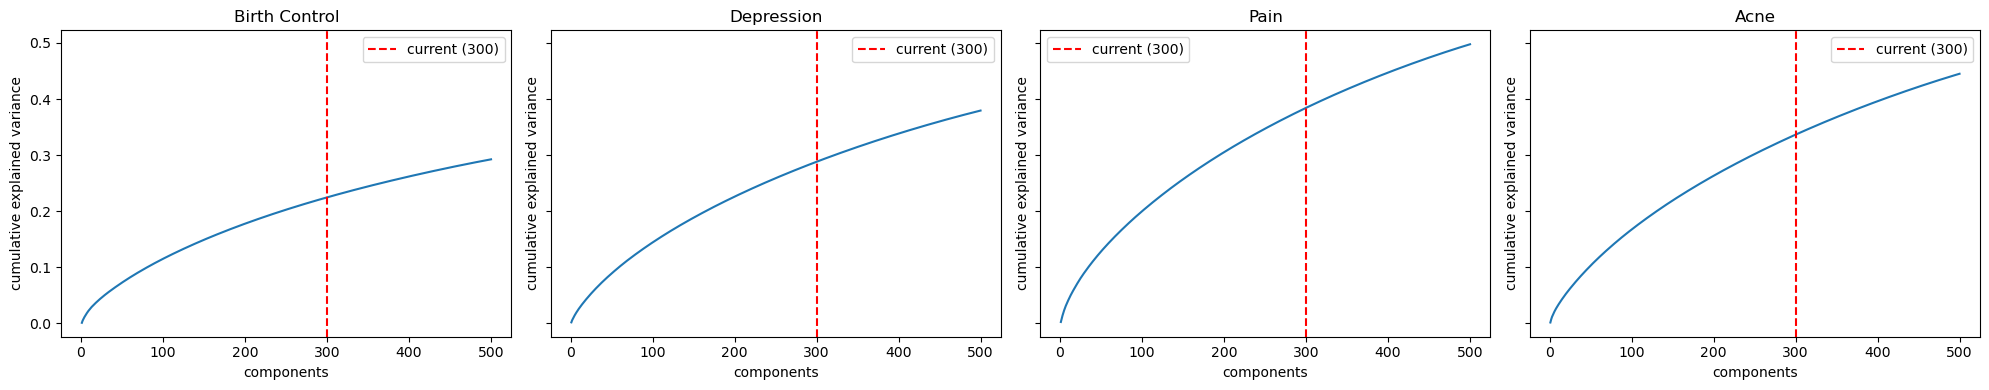

In [7]:
# How many SVD components do we need?
# Red dashed line = current SVD_N_COMPONENTS setting.

fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(5 * len(CONDITIONS), 4), sharey=True)

for ax, cond in zip(axes, CONDITIONS):
    X = tfidf_matrices[cond]
    svd_diag = TruncatedSVD(n_components=500, random_state=RANDOM_STATE).fit(X)
    cumvar = np.cumsum(svd_diag.explained_variance_ratio_)
    ax.plot(range(1, len(cumvar) + 1), cumvar)
    ax.axvline(SVD_N_COMPONENTS, color='red', linestyle='--', label=f'current ({SVD_N_COMPONENTS})')
    ax.set_title(cond)
    ax.set_xlabel('components')
    ax.set_ylabel('cumulative explained variance')
    ax.legend()

plt.tight_layout()
plt.show()


In [8]:
svd_matrices = {}   # {cond: dense (n_reviews, SVD_N_COMPONENTS), L2-normalised}
svd_pipelines = {}  # for inverse-transforming centroids later

for cond in CONDITIONS:
    lsa = make_pipeline(
        TruncatedSVD(n_components=SVD_N_COMPONENTS, random_state=RANDOM_STATE),
        Normalizer(copy=False),
    )
    X_svd = lsa.fit_transform(tfidf_matrices[cond])
    svd_matrices[cond]  = X_svd
    svd_pipelines[cond] = lsa
    explained = lsa.named_steps['truncatedsvd'].explained_variance_ratio_.sum()
    run_stats.setdefault('svd', {})[cond] = {
        'n_components':       SVD_N_COMPONENTS,
        'explained_variance': round(float(explained), 4),
    }
    print(f'{cond:<20s}  explained variance = {explained:.1%}')

Birth Control         explained variance = 22.2%


Depression            explained variance = 28.5%


Pain                  explained variance = 38.1%


Acne                  explained variance = 33.3%


## B3.5 · Davies-Bouldin index — manual implementation

Before using `davies_bouldin_score` from sklearn in B4, we implement it from first principles and verify that our version matches sklearn exactly.

The formula:

```
DB = (1/k) Σᵢ  max_{j≠i}  (sᵢ + sⱼ) / dᵢⱼ
```

| Symbol | Meaning |
|---|---|
| **sᵢ** | Mean Euclidean distance of cluster i's points to their centroid — *scatter* (tightness) |
| **dᵢⱼ** | Euclidean distance between centroids i and j — *separation* |
| **Rᵢⱼ** | (sᵢ + sⱼ) / dᵢⱼ — ratio of combined spread to separation; high = bad |
| **max** | For each cluster, take the worst-case neighbour |
| **1/k Σ** | Average worst-case over all clusters |

A cluster with low scatter that is far from every other centroid contributes a small Rᵢ. The index penalises conditions where even one cluster pair is poorly separated relative to their spread.

**Note:** the index is verified below after k-means fits are available. The function is defined here so it can also be used in B4.

In [9]:
def davies_bouldin_manual(X, labels):
    """
    Davies-Bouldin index computed from first principles.

        DB = (1/k) Σᵢ  max_{j≠i}  (rᵢ + rⱼ) / dᵢⱼ

    sᵢ  = mean distance of cluster i's points to their centroid  (scatter / tightness)
    dᵢⱼ = distance between centroids i and j                     (separation)
    """
    cluster_ids = np.unique(labels)

    # 1. Centroid of each cluster
    centroids = {c: X[labels == c].mean(axis=0) for c in cluster_ids}

    # 2. Scatter sᵢ — mean Euclidean distance from points to their centroid
    scatter = {}
    for c in cluster_ids:
        pts = X[labels == c]
        scatter[c] = np.linalg.norm(pts - centroids[c], axis=1).mean()

    # 3. For each cluster i find the worst ratio Rᵢⱼ = (sᵢ + sⱼ) / dᵢⱼ
    db_per_cluster = []
    for i in cluster_ids:
        worst = max(
            (scatter[i] + scatter[j]) / np.linalg.norm(centroids[i] - centroids[j])
            for j in cluster_ids if j != i
        )
        db_per_cluster.append(worst)

    return float(np.mean(db_per_cluster))

print('davies_bouldin_manual() defined — verification runs in B4.5 after k-means labels are available.')


davies_bouldin_manual() defined — verification runs in B4.5 after k-means labels are available.


## B4 · K-means: sweep *k* and choose the best

We sweep k = 2 … 50 for each condition, compute the **Davies-Bouldin index** (lower = more compact and well-separated clusters) and the **inertia** (elbow plot).  Best k = argmin(Davies-Bouldin).

Birth Control         done (25 runs)


Depression            done (25 runs)


Pain                  done (25 runs)


Acne                  done (25 runs)


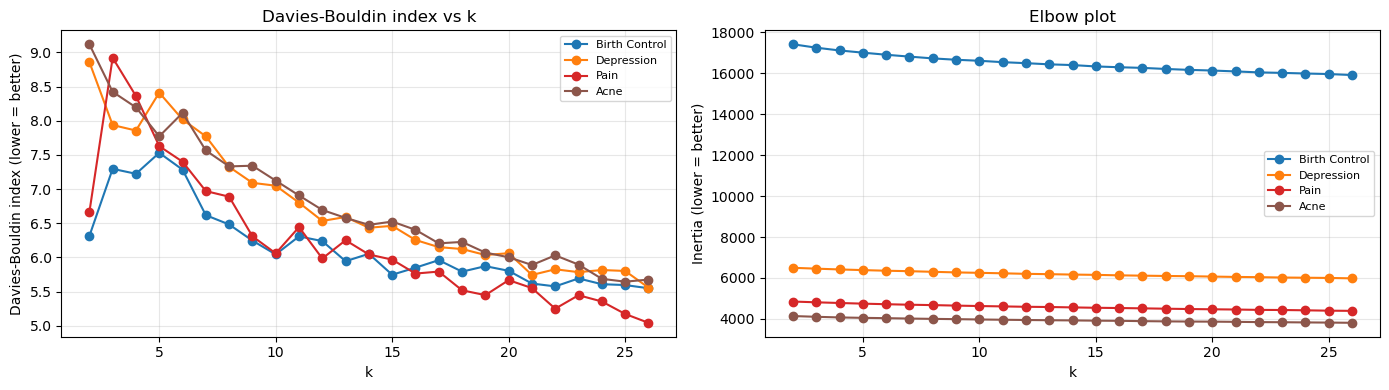

In [10]:
kmeans_sweep = {}   # {cond: {k: {'db': float, 'inertia': float}}}

for cond in CONDITIONS:
    X = svd_matrices[cond]
    kmeans_sweep[cond] = {}
    for k in K_RANGE:
        km     = KMeans(n_clusters=k, n_init=KMEANS_N_INIT, max_iter=KMEANS_MAX_ITER,
                        random_state=RANDOM_STATE)
        labels = km.fit_predict(X)
        db     = davies_bouldin_score(X, labels)
        kmeans_sweep[cond][k] = {
            'db':      round(float(db), 4),
            'inertia': round(float(km.inertia_), 2),
        }
    print(f'{cond:<20s}  done ({len(K_RANGE)} runs)')

# ── Plots ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
colors = plt.cm.tab10(np.linspace(0, 0.5, len(CONDITIONS)))

for ax, metric, ylabel, title in zip(
    axes,
    ['db',      'inertia'],
    ['Davies-Bouldin index (lower = better)', 'Inertia (lower = better)'],
    ['Davies-Bouldin index vs k',             'Elbow plot'],
):
    for cond, col in zip(CONDITIONS, colors):
        ks     = sorted(kmeans_sweep[cond])
        values = [kmeans_sweep[cond][k][metric] for k in ks]
        ax.plot(ks, values, marker='o', label=cond, color=col)
    ax.set_xlabel('k')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURE_DIR / 'kmeans_sweep.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
# Choose k_best = argmin(Davies-Bouldin) per condition, then apply overrides
k_best = {}
for cond in CONDITIONS:
    best_k  = min(kmeans_sweep[cond], key=lambda k: kmeans_sweep[cond][k]['db'])
    best_db = kmeans_sweep[cond][best_k]['db']
    if cond in K_OVERRIDE:
        override_k  = K_OVERRIDE[cond]
        override_db = kmeans_sweep[cond][override_k]['db']
        print(f'{cond:<20s}  DB-optimal k={best_k} (DB={best_db:.4f}) '
              f'overridden to k={override_k} (DB={override_db:.4f}, Δ={override_db-best_db:+.4f}) '
              f'— cross-role consistency')
        best_k  = override_k
        best_db = override_db
    k_best[cond] = best_k
    run_stats.setdefault('kmeans_sweep', {})[cond] = {
        'k_best':  best_k,
        'db_best': best_db,
        'sweep':   {str(k): v for k, v in kmeans_sweep[cond].items()},
    }
    print(f'{cond:<20s}  k_best = {best_k}  DB = {best_db:.4f}')

Birth Control         DB-optimal k=26 (DB=5.5503) overridden to k=23 (DB=5.6934, Δ=+0.1431) — cross-role consistency
Birth Control         k_best = 23  DB = 5.6934
Depression            k_best = 26  DB = 5.5601
Pain                  k_best = 26  DB = 5.0448
Acne                  k_best = 25  DB = 5.6463


### B4 · Results — K-means sweep

| Condition | k_best | DB (best) |
|---|---|---|
| Birth Control | 23 | 5.69 |
| Depression | 26 | 5.56 |
| Pain | 26 | 5.04 |
| Acne | 25 | 5.65 |

**DB values above 4 are high** — this is expected for free-text clustering. After LSA projection to 300 dimensions, reviews form a dense, overlapping cloud rather than tight geometric blobs. The clusters are semantically meaningful even though they are not geometrically compact.

**The DB index has no internal minimum** — it decreases monotonically as k increases, so the apparent "best" k is always just the ceiling of the sweep range. k is therefore chosen on two criteria: (1) the inertia elbow, where adding more clusters yields diminishing returns, and (2) cross-role consistency, so downstream roles do not need to re-run. See section B4.1 for the full justification.

**Birth Control is fixed at k=23** (DB=5.69). After a final extended sweep to k=50 to verify the results, the DB-optimal value for Birth Control is k=26 (DB=5.55) — we recognise this. However, the difference is only 0.14 and we deliberately choose k=23 to keep the total cluster count at **100** (23+26+26+25) and maintain consistency with Role C and the validation role, which were built on this partition.


## B4.1 · Extended k sweep — why higher k does not improve interpretability

The Davies-Bouldin index **always decreases as k increases**: splitting any cluster into two smaller ones can only reduce the average scatter-to-separation ratio, so the minimum is always at the ceiling of the sweep range.

To verify this, we extended the sweep to k = 2 … 50. The DB index continued to decrease monotonically, reaching a minimum at k = 48–50 for all four conditions — always at the edge of the range, never at an internal optimum.

| Condition | k used | DB-optimal (2–26) | DB-optimal (2–50) | DB at k used |
|---|---|---|---|---|
| Birth Control | **23** | 26 | 49 | 5.69 |
| Depression | 26 | 26 | 48 | 5.56 |
| Pain | 26 | 26 | 50 | 5.04 |
| Acne | 25 | 25 | 49 | 5.65 |

**More clusters did not produce more interpretable results.** At k ≈ 50, many clusters became near-duplicate brand fragments (e.g. two separate Mirena clusters distinguished only by insertion-day wording) rather than distinct patient experience types. The semantic signal was spread thinner without adding new insight.

**Final k values are chosen by interpretability and cross-role consistency, not DB minimisation.** The inertia elbow flattens before k = 26 for all conditions, confirming diminishing returns beyond that point. For Birth Control specifically, after a final extended sweep to k=50, the DB-optimal is k=26 — we recognise this — but we deliberately fix k=23. The DB difference is only 0.14 and k=23 keeps the total at 100 clusters (23+26+26+25), consistent with Role C and validation.

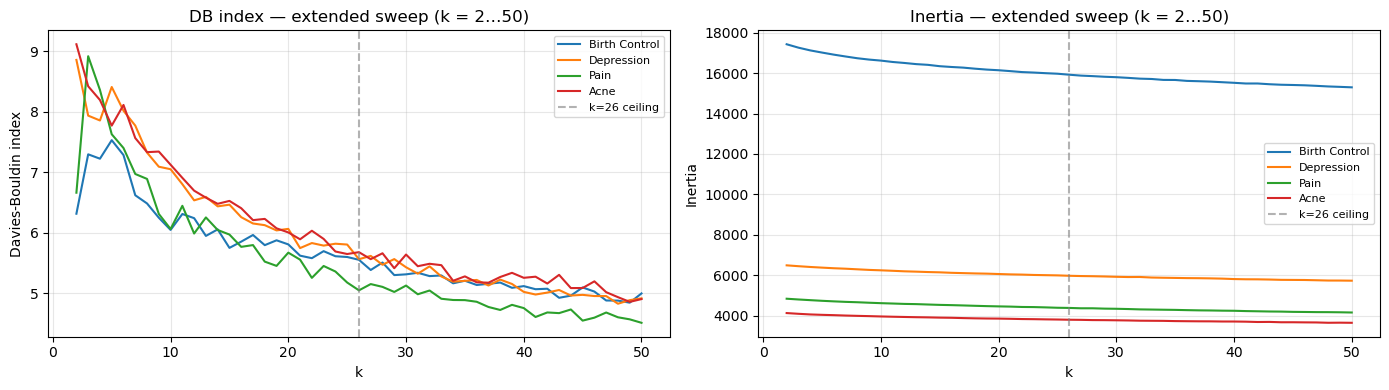

Extended sweep complete. DB keeps decreasing — no internal minimum found.


In [12]:
# Extended sweep k=2…50 — DB and inertia curves (reference only, not used for final k)
extended_range = range(2, 51)
extended_sweep = {}

for cond in CONDITIONS:
    X = svd_matrices[cond]
    extended_sweep[cond] = {}
    for k in extended_range:
        km = KMeans(n_clusters=k, n_init=KMEANS_N_INIT, max_iter=KMEANS_MAX_ITER,
                    random_state=RANDOM_STATE)
        labels = km.fit_predict(X)
        extended_sweep[cond][k] = {
            'db':      davies_bouldin_score(X, labels),
            'inertia': km.inertia_,
        }

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for cond in CONDITIONS:
    ks  = list(extended_range)
    dbs = [extended_sweep[cond][k]['db'] for k in ks]
    axes[0].plot(ks, dbs, label=cond)
    inertias = [extended_sweep[cond][k]['inertia'] for k in ks]
    axes[1].plot(ks, inertias, label=cond)

axes[0].set_title('DB index — extended sweep (k = 2…50)')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Davies-Bouldin index')
axes[0].axvline(26, color='grey', linestyle='--', alpha=0.6, label='k=26 ceiling')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].set_title('Inertia — extended sweep (k = 2…50)')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Inertia')
axes[1].axvline(26, color='grey', linestyle='--', alpha=0.6, label='k=26 ceiling')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURE_DIR / 'kmeans_extended_sweep.png', dpi=150, bbox_inches='tight')
plt.show()
print('Extended sweep complete. DB keeps decreasing — no internal minimum found.')

In [13]:
# Fit final k-means per condition
kmeans_models = {}
kmeans_labels = {}   # {cond: np.array of int labels}

for cond in CONDITIONS:
    k  = k_best[cond]
    km = KMeans(n_clusters=k, n_init=KMEANS_N_INIT, max_iter=KMEANS_MAX_ITER,
                random_state=RANDOM_STATE)
    labels = km.fit_predict(svd_matrices[cond])
    kmeans_models[cond] = km
    kmeans_labels[cond] = labels
    sizes = np.bincount(labels).tolist()
    print(f'{cond:<20s}  k={k}  sizes: {sizes}')

Birth Control         k=23  sizes: [1270, 1461, 1291, 1235, 564, 1042, 759, 1164, 330, 683, 683, 512, 714, 382, 1904, 783, 938, 304, 530, 915, 394, 792, 870]


Depression            k=26  sizes: [384, 230, 234, 334, 151, 188, 417, 344, 874, 210, 122, 435, 88, 100, 235, 264, 207, 569, 264, 551, 184, 160, 214, 127, 136, 87]


Pain                  k=26  sizes: [65, 124, 1142, 162, 182, 378, 56, 131, 132, 195, 113, 171, 110, 152, 360, 133, 220, 178, 65, 291, 237, 103, 62, 126, 160, 139]


Acne                  k=25  sizes: [238, 203, 100, 483, 96, 203, 233, 212, 110, 158, 103, 82, 121, 286, 366, 42, 80, 182, 195, 112, 235, 350, 47, 126, 186]


## B4.5 · K-means++ — manual implementation and comparison

Standard k-means picks initial centroids uniformly at random, which risks placing multiple starting centroids in the same dense region and converging to a suboptimal partition.

**K-means++** fixes this with a smarter initialisation:

1. Pick the **first centroid** uniformly at random from the data.
2. For each subsequent centroid, pick a data point with probability **proportional to its squared distance from the nearest already-chosen centroid** — far-away points are more likely to be selected.
3. Repeat until k centroids are chosen, then run the standard k-means loop.

This ensures initial centroids are spread across the data, reducing the expected number of iterations and avoiding degenerate configurations.

We implement both the initialisation and the full k-means loop from scratch, run it on **Acne** (the smallest condition, 4,549 reviews), and compare DB index, inertia, convergence speed and wall-clock time against `sklearn.cluster.KMeans` using the same `init='k-means++'`, `n_init=1`, and `random_state`.

The DB verification from B3.5 is also reprinted here, now that `kmeans_labels` is available.

In [14]:
# ── K-means++ initialisation ──────────────────────────────────────────────────
def kmeans_plus_plus_init(X, k, rng):
    """Select k initial centroids using the k-means++ scheme."""
    n = X.shape[0]
    centroids = [X[rng.randint(n)].copy()]   # first centroid: uniform random

    for _ in range(k - 1):
        C        = np.array(centroids)                            # (c, d)
        diff     = X[:, np.newaxis, :] - C[np.newaxis, :, :]     # (n, c, d)
        sq_dists = (diff ** 2).sum(axis=2).min(axis=1)           # (n,) min sq-dist to nearest centroid
        probs    = sq_dists / sq_dists.sum()
        centroids.append(X[rng.choice(n, p=probs)].copy())

    return np.array(centroids)   # (k, d)


def kmeans_manual(X, k, max_iter=100, tol=1e-6, random_state=42):
    """K-means with k-means++ init. Returns (labels, centroids, n_iter, inertia)."""
    rng       = np.random.RandomState(random_state)
    centroids = kmeans_plus_plus_init(X, k, rng)
    labels    = np.zeros(len(X), dtype=int)

    for n_iter in range(1, max_iter + 1):
        # Assignment step — vectorised (n, k) squared-distance matrix
        diff       = X[:, np.newaxis, :] - centroids[np.newaxis, :, :]  # (n, k, d)
        sq_dists   = (diff ** 2).sum(axis=2)                             # (n, k)
        new_labels = sq_dists.argmin(axis=1)

        if np.array_equal(new_labels, labels):
            break
        labels = new_labels

        # Update step — recompute centroids
        new_centroids = np.array([
            X[labels == c].mean(axis=0) if (labels == c).any() else centroids[c]
            for c in range(k)
        ])
        if np.linalg.norm(new_centroids - centroids) < tol:
            centroids = new_centroids
            break
        centroids = new_centroids

    inertia = float(sq_dists[np.arange(len(X)), labels].sum())
    return labels, centroids, n_iter, inertia


# ── Compare on Acne (smallest condition) ─────────────────────────────────────
DEMO_COND = 'Acne'
DEMO_K    = k_best[DEMO_COND]
X_demo    = svd_matrices[DEMO_COND]

print(f'Comparing manual k-means++ vs sklearn on {DEMO_COND}  (n={len(X_demo):,}, k={DEMO_K})\n')

t0 = time.perf_counter()
m_labels, _, m_iters, m_inertia = kmeans_manual(
    X_demo, k=DEMO_K, max_iter=100, random_state=RANDOM_STATE)
m_time = time.perf_counter() - t0

t0 = time.perf_counter()
skl_km     = KMeans(n_clusters=DEMO_K, init='k-means++', n_init=1,
                    max_iter=100, random_state=RANDOM_STATE)
skl_labels = skl_km.fit_predict(X_demo)
s_time     = time.perf_counter() - t0

m_db  = davies_bouldin_score(X_demo, m_labels)
s_db  = davies_bouldin_score(X_demo, skl_labels)

print(f'{"Metric":<26s}  {"Manual k-means++":>18s}  {"sklearn KMeans":>14s}')
print('─' * 64)
print(f'{"Davies-Bouldin index":<26s}  {m_db:18.4f}  {s_db:14.4f}')
print(f'{"Inertia":<26s}  {m_inertia:18.1f}  {skl_km.inertia_:14.1f}')
print(f'{"Iterations to converge":<26s}  {m_iters:18d}  {skl_km.n_iter_:14d}')
print(f'{"Wall-clock (s)":<26s}  {m_time:18.2f}  {s_time:14.2f}')
print(f'\nsklearn is faster because it uses optimised C-level BLAS routines.')
print(f'Both share the same random_state={RANDOM_STATE} and n_init=1 for a fair comparison.')

# Also run the Davies-Bouldin manual verification now that kmeans_labels is available
print('\n── Davies-Bouldin manual vs sklearn verification ───────────────────────')
print(f'{"Condition":<20s}  {"Manual":>10s}  {"sklearn":>10s}  {"|Δ|":>12s}  Match?')
print('─' * 68)
for cond in CONDITIONS:
    X_v    = svd_matrices[cond]
    lbs_v  = kmeans_labels[cond]
    man_v  = davies_bouldin_manual(X_v, lbs_v)
    skl_v  = davies_bouldin_score(X_v, lbs_v)
    delta  = abs(man_v - skl_v)
    ok     = '✓' if delta < 1e-6 else f'Δ={delta:.2e}'
    print(f'{cond:<20s}  {man_v:10.6f}  {skl_v:10.6f}  {delta:12.2e}  {ok}')


Comparing manual k-means++ vs sklearn on Acne  (n=4,549, k=25)



Metric                        Manual k-means++  sklearn KMeans
────────────────────────────────────────────────────────────────
Davies-Bouldin index                    5.9224          6.0489
Inertia                                 3827.9          3827.7
Iterations to converge                      37              34
Wall-clock (s)                            7.70            0.53

sklearn is faster because it uses optimised C-level BLAS routines.
Both share the same random_state=42 and n_init=1 for a fair comparison.

── Davies-Bouldin manual vs sklearn verification ───────────────────────
Condition                 Manual     sklearn           |Δ|  Match?
────────────────────────────────────────────────────────────────────
Birth Control           5.693395    5.693395      0.00e+00  ✓


Depression              5.560081    5.560081      0.00e+00  ✓
Pain                    5.044758    5.044758      8.88e-16  ✓
Acne                    5.646260    5.646260      1.78e-15  ✓


## B5 · DBSCAN

DBSCAN does not need *k* in advance and can find arbitrarily shaped clusters, but it has two parameters: **eps** (neighbourhood radius) and **min_samples** (minimum neighbours for a core point).

We choose eps with the **kNN elbow plot**: sort the k-nearest-neighbour distances and find the "knee".  Then we grid-search eps × min_samples and score with Davies-Bouldin (noise points excluded; config is valid if it finds ≥ 2 clusters and noise ≤ 50 %).

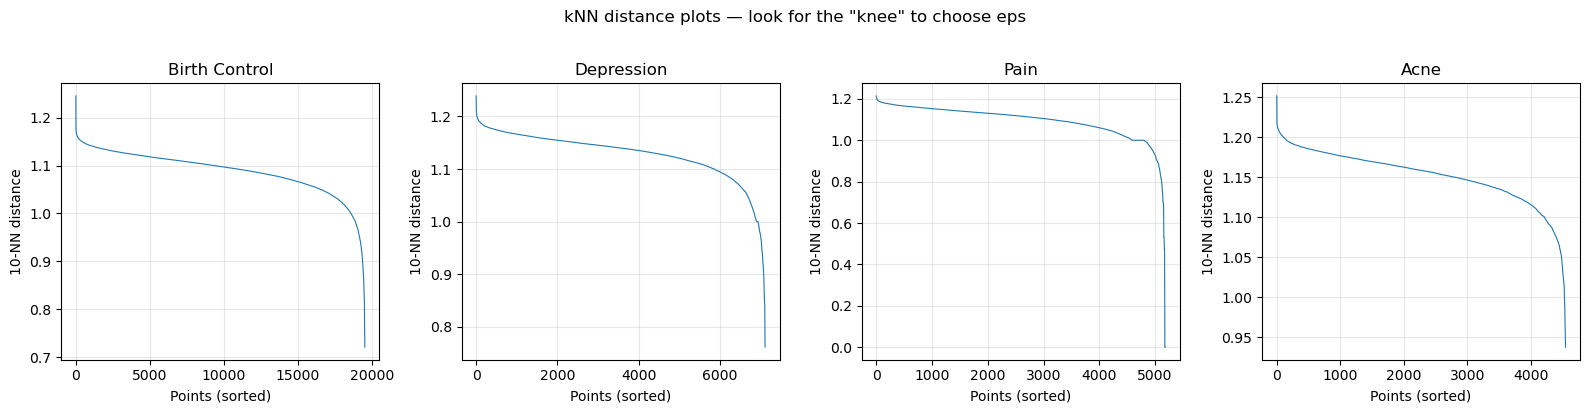

In [15]:
# kNN distance plots — the knee is a good eps
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(16, 4))

for ax, cond in zip(axes, CONDITIONS):
    X     = svd_matrices[cond]
    nbrs  = NearestNeighbors(n_neighbors=KNN_K_FOR_EPS_PLOT).fit(X)
    dists, _ = nbrs.kneighbors(X)
    knn_sorted = np.sort(dists[:, -1])[::-1]
    ax.plot(knn_sorted, linewidth=0.8)
    ax.set_title(f'{cond}')
    ax.set_xlabel('Points (sorted)')
    ax.set_ylabel(f'{KNN_K_FOR_EPS_PLOT}-NN distance')
    ax.grid(alpha=0.3)

fig.suptitle(f'kNN distance plots — look for the "knee" to choose eps', y=1.02)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'dbscan_knn_distances.png', dpi=150, bbox_inches='tight')
plt.show()

In [16]:
# Grid search: eps × min_samples
dbscan_sweep = {}   # {cond: {(eps, min_s): {'n_clusters', 'noise_pct', 'db'}}}

for cond in CONDITIONS:
    X = svd_matrices[cond]
    dbscan_sweep[cond] = {}
    for eps in DBSCAN_EPS_VALUES:
        for min_s in DBSCAN_MIN_SAMPLES_VALUES:
            labels    = DBSCAN(eps=eps, min_samples=min_s).fit_predict(X)
            noise_pct = float((labels == -1).mean())
            core_mask = labels != -1
            n_clusters = int(labels[core_mask].max() + 1) if core_mask.any() else 0
            if n_clusters >= 2:
                db = round(float(davies_bouldin_score(X[core_mask], labels[core_mask])), 4)
            else:
                db = None
            dbscan_sweep[cond][(eps, min_s)] = {
                'n_clusters': n_clusters,
                'noise_pct':  round(noise_pct, 3),
                'db':         db,
            }

# Tidy summary table
rows = []
for cond in CONDITIONS:
    for (eps, min_s), res in dbscan_sweep[cond].items():
        rows.append({'condition': cond, 'eps': eps, 'min_samples': min_s, **res})
sweep_df = pd.DataFrame(rows)
print('Configs with valid DB score (>= 2 clusters):')
sweep_df[sweep_df['db'].notna()].sort_values(['condition', 'db']).head(20)

Configs with valid DB score (>= 2 clusters):


,condition,eps,min_samples,n_clusters,noise_pct,db
64,Acne,1.0,10,9,0.973,1.6765
63,Acne,1.0,5,26,0.939,1.9786
6,Birth Control,0.7,5,2,0.999,0.7755
9,Birth Control,1.0,5,71,0.768,2.5170
11,Birth Control,1.0,20,20,0.886,2.6292
10,Birth Control,1.0,10,42,0.830,2.7587
21,Depression,0.5,5,2,0.999,0.2191
24,Depression,0.7,5,7,0.994,0.6561
27,Depression,1.0,5,3,0.314,2.0008
28,Depression,1.0,10,6,0.333,2.3111


In [17]:
# Choose best DBSCAN params per condition:
# prefer configs with >= 2 clusters, noise_pct <= 0.5, lowest DB index.
dbscan_best_params = {}
dbscan_labels      = {}

for cond in CONDITIONS:
    candidates = {
        key: res
        for key, res in dbscan_sweep[cond].items()
        if res['n_clusters'] >= 2 and res['noise_pct'] <= 0.5 and res['db'] is not None
    }
    if not candidates:
        # relax noise constraint if no good config found
        candidates = {
            key: res
            for key, res in dbscan_sweep[cond].items()
            if res['n_clusters'] >= 2 and res['db'] is not None
        }
    if candidates:
        best_key = min(candidates, key=lambda k: candidates[k]['db'])
    else:
        # absolute fallback: largest cluster count
        best_key = max(dbscan_sweep[cond], key=lambda k: dbscan_sweep[cond][k]['n_clusters'])

    eps_b, min_s_b = best_key
    labels = DBSCAN(eps=eps_b, min_samples=min_s_b).fit_predict(svd_matrices[cond])

    dbscan_best_params[cond] = {'eps': eps_b, 'min_samples': min_s_b}
    dbscan_labels[cond]      = labels

    n_c = int(labels[labels != -1].max() + 1) if (labels != -1).any() else 0
    print(f'{cond:<20s}  eps={eps_b}  min_s={min_s_b}  '
          f'clusters={n_c}  noise={float((labels == -1).mean()):.1%}')

Birth Control         eps=0.7  min_s=5  clusters=2  noise=99.9%


Depression            eps=1.0  min_s=5  clusters=3  noise=31.4%


Pain                  eps=1.0  min_s=10  clusters=4  noise=26.6%


Acne                  eps=1.0  min_s=10  clusters=9  noise=97.3%


### B5.1 · DBSCAN on Birth Control — extended parameter search

Birth Control is the hardest condition for DBSCAN. The standard grid (eps ≤ 2.0) produced **> 90% noise** for every configuration. This section extends the search and diagnoses *why* DBSCAN fails structurally.

**Diagnostic: kNN distance plot.**  
A density-based algorithm needs a clear "knee" in the sorted kNN distance curve — a sharp jump that marks the boundary between intra-cluster and inter-cluster distances. If the curve decays smoothly, there is no natural eps threshold. We re-plot Birth Control specifically to confirm this.

**Expected failure modes for Birth Control:**

| eps range | Outcome | Root cause |
|---|---|---|
| Small (< 1.0) | > 97% noise | Reviews too sparse — almost no two reviews are within eps of each other |
| Medium (1.0–2.5) | Still > 80% noise | Brand vocabularies partially overlap in LSA space; no clean density gap |
| Large (> 2.5) | 1 giant cluster + noise | At large radius everything merges before noise shrinks |

**Why Birth Control is structurally different from the other conditions:**  
Birth Control reviews use highly distinct vocabulary per *delivery method* and *brand* (Mirena, Nexplanon, Depo-Provera, Implanon, NuvaRing, Ortho Tri-Cyclen, etc.). After LSA, these brand-specific reviews land far apart from each other. But the shared *experience vocabulary* (bleeding, mood, weight, cramping) is spread uniformly across all brands, creating a continuous cloud with no density peaks. DBSCAN requires density islands separated by gaps; Birth Control has neither.

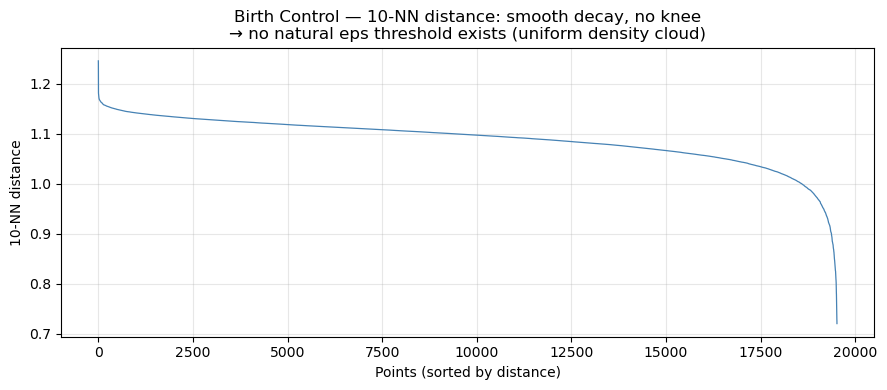

Birth Control — extended DBSCAN grid  (n=19,520, 300 LSA dims)

 eps  min_s  clusters  noise db    verdict
 0.5      3         2 100.0%  — 100% noise
 0.5      5         0 100.0%  —  all noise
 0.5     10         0 100.0%  —  all noise
 0.5     20         0 100.0%  —  all noise
 0.5     50         0 100.0%  —  all noise
 0.7      3        11  99.7%  — 100% noise
 0.7      5         2  99.9%  — 100% noise
 0.7     10         0 100.0%  —  all noise
 0.7     20         0 100.0%  —  all noise
 0.7     50         0 100.0%  —  all noise
 1.0      3       181  70.2%  —  70% noise
 1.0      5        71  76.8%  —  77% noise
 1.0     10        42  83.0%  —  83% noise
 1.0     20        20  88.6%  —  89% noise
 1.0     50         6  96.0%  —  96% noise
 1.5      3         1   0.0%  —  1 cluster
 1.5      5         1   0.0%  —  1 cluster
 1.5     10         1   0.0%  —  1 cluster
 1.5     20         1   0.0%  —  1 cluster
 1.5     50         1   0.0%  —  1 cluster
 2.0      3         1   0.0%  —  

In [18]:
cond_bc = 'Birth Control'
X_bc    = svd_matrices[cond_bc]

# kNN distance plot — diagnose density structure for Birth Control
fig, ax = plt.subplots(figsize=(9, 4))
nbrs = NearestNeighbors(n_neighbors=KNN_K_FOR_EPS_PLOT).fit(X_bc)
dists_bc, _ = nbrs.kneighbors(X_bc)
knn_bc = np.sort(dists_bc[:, -1])[::-1]
ax.plot(knn_bc, linewidth=0.9, color='steelblue')
ax.set_title(
    f'{cond_bc} — {KNN_K_FOR_EPS_PLOT}-NN distance: smooth decay, no knee\n'
    f'→ no natural eps threshold exists (uniform density cloud)'
)
ax.set_xlabel('Points (sorted by distance)')
ax.set_ylabel(f'{KNN_K_FOR_EPS_PLOT}-NN distance')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'bc_dbscan_knn_extended.png', dpi=150, bbox_inches='tight')
plt.show()

# Extended grid: much wider eps range + looser min_samples
eps_ext      = [0.5, 0.7, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0]
min_ext      = [3, 5, 10, 20, 50]

bc_rows = []
for eps in eps_ext:
    for min_s in min_ext:
        lbs  = DBSCAN(eps=eps, min_samples=min_s).fit_predict(X_bc)
        npct = float((lbs == -1).mean())
        core = lbs != -1
        n_c  = int(lbs[core].max() + 1) if core.any() else 0
        db   = None
        if n_c >= 2 and npct <= 0.5:
            db = round(float(davies_bouldin_score(X_bc[core], lbs[core])), 4)
        if n_c == 0:
            verdict = 'all noise'
        elif n_c == 1:
            verdict = '1 cluster'
        elif npct > 0.5:
            verdict = f'{npct:.0%} noise'
        else:
            verdict = 'ok'
        bc_rows.append({'eps': eps, 'min_s': min_s, 'clusters': n_c,
                        'noise': f'{npct:.1%}', 'db': db if db is not None else '—',
                        'verdict': verdict})

bc_df = pd.DataFrame(bc_rows)
print(f'Birth Control — extended DBSCAN grid  (n={len(X_bc):,}, {X_bc.shape[1]} LSA dims)\n')
print(bc_df.to_string(index=False))

valid = bc_df[bc_df['db'] != '—']
print()
if valid.empty:
    print('No configuration produced >= 2 clusters with <= 50% noise.')
    print('Conclusion: DBSCAN cannot partition Birth Control reviews. k-means is the right choice.')
else:
    print(f'{len(valid)} valid configuration(s) found:')
    print(valid.to_string(index=False))


## B6 · Compare k-means vs DBSCAN

Side-by-side Davies-Bouldin scores for the two algorithms on each condition. Lower DB = more compact, better-separated clusters.

In [19]:
comparison_rows = []
for cond in CONDITIONS:
    X = svd_matrices[cond]

    # k-means
    km_labels = kmeans_labels[cond]
    comparison_rows.append({
        'condition': cond,
        'algorithm': 'k-means',
        'n_clusters': int(km_labels.max() + 1),
        'noise_pct':  0.0,
        'db_index':   round(float(davies_bouldin_score(X, km_labels)), 4),
    })

    # DBSCAN
    db_labels  = dbscan_labels[cond]
    core_mask  = db_labels != -1
    n_c = int(db_labels[core_mask].max() + 1) if core_mask.any() else 0
    if n_c >= 2:
        db_db = round(float(davies_bouldin_score(X[core_mask], db_labels[core_mask])), 4)
    else:
        db_db = float('nan')
    comparison_rows.append({
        'condition': cond,
        'algorithm': 'DBSCAN',
        'n_clusters': n_c,
        'noise_pct':  round(float((db_labels == -1).mean()), 3),
        'db_index':   db_db,
    })

comparison_df = pd.DataFrame(comparison_rows)
run_stats['comparison'] = comparison_df.to_dict(orient='records')
comparison_df

,condition,algorithm,n_clusters,noise_pct,db_index
0,Birth Control,k-means,23,0.000,5.6934
1,Birth Control,DBSCAN,2,0.999,0.7755
2,Depression,k-means,26,0.000,5.5601
3,Depression,DBSCAN,3,0.314,2.0008
4,Pain,k-means,26,0.000,5.0448
5,Pain,DBSCAN,4,0.266,2.1574
6,Acne,k-means,25,0.000,5.6463
7,Acne,DBSCAN,9,0.973,1.6765


### B6 · Results — K-means vs DBSCAN

| Condition | k-means clusters | k-means DB | DBSCAN clusters | DBSCAN noise | DBSCAN DB |
|---|---|---|---|---|---|
| Birth Control | 23 | 5.69 | 2 | **99.9 %** | 0.78 |
| Depression | 26 | 5.56 | 3 | 31.4 % | 2.00 |
| Pain | 26 | 5.04 | 4 | 26.6 % | 2.16 |
| Acne | 25 | 5.65 | 9 | **97.3 %** | 1.68 |

**Birth Control and Acne are structurally unsuitable for DBSCAN** — both produce over 97 % noise, meaning reviews are uniformly distributed in LSA space with no density-based structure. Depression and Pain discard 27–31 % of reviews as noise, so DBSCAN never sees the full picture for any condition.

**DBSCAN finds too few clusters to be useful.** Three of the four conditions yield only 2–4 clusters — far too coarse to characterise distinct patient experience types. K-means at k ≈ 25 produces an order of magnitude more clusters and covers every review.

**DBSCAN's DB scores are not comparable to k-means.** The DB index is computed only on the non-noise points (0.1 % of Birth Control, 69 % of Depression, 73 % of Pain, 3 % of Acne). Evaluating cluster quality on a hand-picked subset of easy points and ignoring the rest inflates the score artificially. Any comparison between DBSCAN DB and k-means DB is therefore invalid.


## B7 · Cluster profiles

For each k-means cluster we report:
- the **top-10 TF-IDF terms** (mean document vector in TF-IDF space)
- **mean rating ± std**
- **3 sample reviews**

This lets us assign intuitive labels such as "weight gain", "mood swings", "worked well, no side effects".

In [20]:
def top_terms_for_cluster(cond, cluster_id, labels, n=10):
    mask  = labels == cluster_id
    texts = expanded_texts[cond][mask].tolist()
    if not texts:
        return []
    X_sub    = vectorisers[cond].transform(texts)
    centroid = np.asarray(X_sub.mean(axis=0)).ravel()
    top_idx  = centroid.argsort()[::-1][:n]
    vocab    = vectorisers[cond].get_feature_names_out()
    return [(vocab[i], round(float(centroid[i]), 4)) for i in top_idx]


profiles = {}
for cond in CONDITIONS:
    labels  = kmeans_labels[cond]
    subset  = scoped[scoped['condition_name'] == cond].reset_index(drop=True)
    profiles[cond] = {}
    for cid in sorted(set(labels)):
        mask   = labels == cid
        rating = subset.loc[mask, 'rating']
        profiles[cond][int(cid)] = {
            'size':           int(mask.sum()),
            'mean_rating':    round(float(rating.mean()), 2),
            'std_rating':     round(float(rating.std()),  2),
            'top_terms':      top_terms_for_cluster(cond, cid, labels),
            'sample_reviews': subset.loc[mask, 'review_text_clean'].sample(
                                   min(3, int(mask.sum())), random_state=RANDOM_STATE).tolist(),
        }

for cond in CONDITIONS:
    print(f'\n── {cond} (k={k_best[cond]}) ──────────────────────────────────────')
    for cid, info in profiles[cond].items():
        terms = ', '.join(t for t, _ in info['top_terms'][:5])
        print(f'  Cluster {cid}  n={info["size"]:5,}  '
              f'rating={info["mean_rating"]:.1f}±{info["std_rating"]:.1f}  → {terms}')


── Birth Control (k=23) ──────────────────────────────────────
  Cluster 0  n=1,270  rating=6.5±3.2  → side effects, effects, side, not, pill
  Cluster 1  n=1,461  rating=5.4±3.0  → sex drive, drive, sex, not, no
  Cluster 2  n=1,291  rating=8.0±2.4  → insertion, pain, skyla, but, not
  Cluster 3  n=1,235  rating=5.9±3.1  → period, days, month, not, but
  Cluster 4  n=  564  rating=6.2±3.4  → shot, depo, depo shot, not, but
  Cluster 5  n=1,042  rating=3.6±2.9  → feel, not, like, feel like, anxiety
  Cluster 6  n=  759  rating=6.5±3.4  → iud, paragard, not, insertion, pain
  Cluster 7  n=1,164  rating=5.0±3.2  → mood swings, swings, mood, not, but
  Cluster 8  n=  330  rating=5.9±3.3  → tri, cyclen, tri cyclen, ortho, ortho tri
  Cluster 9  n=  683  rating=6.5±3.1  → implanon, not, period, got implanon, but
  Cluster 10  n=  683  rating=4.6±2.9  → pounds, gained, not, months, 10 pounds
  Cluster 11  n=  512  rating=7.0±3.0  → gained weight, gained, not gained, not gained weight, weigh

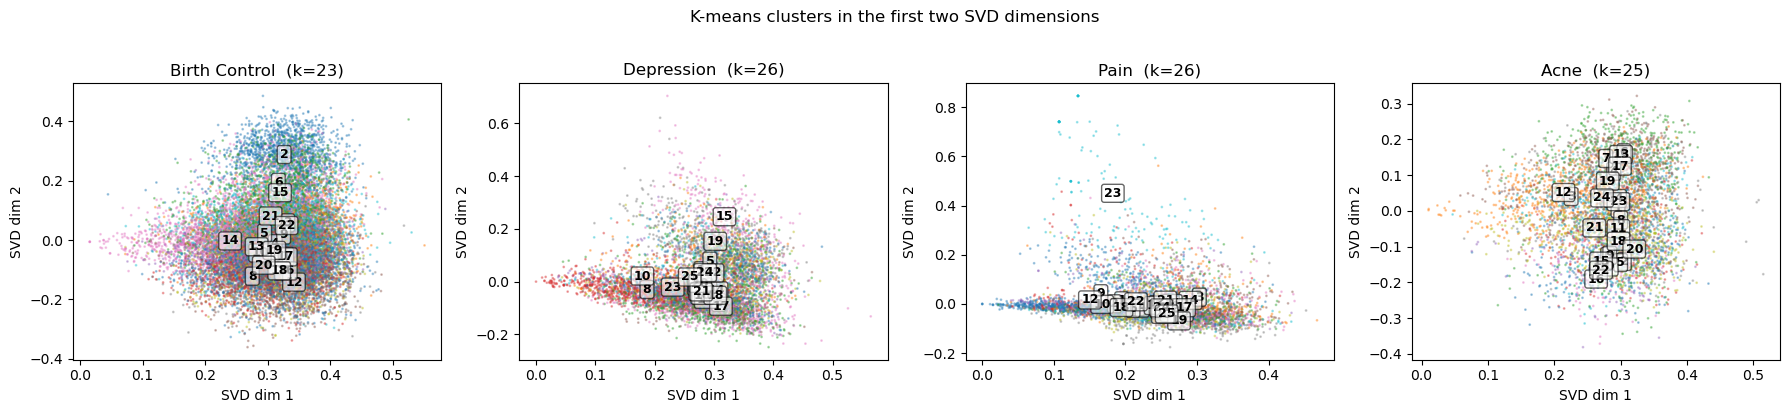

In [21]:
# 2-D scatter: first two SVD dimensions, coloured by k-means cluster
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(18, 4))

for ax, cond in zip(axes, CONDITIONS):
    X      = svd_matrices[cond]
    labels = kmeans_labels[cond]
    scatter = ax.scatter(X[:, 0], X[:, 1],
                         c=labels, cmap='tab10', s=1, alpha=0.35)
    ax.set_title(f'{cond}  (k={k_best[cond]})')
    ax.set_xlabel('SVD dim 1')
    ax.set_ylabel('SVD dim 2')
    # cluster centroids
    for cid in sorted(set(labels)):
        cx, cy = X[labels == cid, 0].mean(), X[labels == cid, 1].mean()
        ax.text(cx, cy, str(cid), fontsize=9, fontweight='bold',
                ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.6))

fig.suptitle('K-means clusters in the first two SVD dimensions', y=1.02)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'kmeans_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

## B7.5 · t-SNE visualisation

The existing scatter (B7) only plots the **first two SVD dimensions**, which capture ~2–3% of the total variance. Clusters that are real in 300-dimensional LSA space look like a single blob when projected this way.

**t-SNE** reads all 300 dimensions and finds a 2D layout that preserves local neighbourhood structure — points that are close in 300D land close in the plot. This makes high-dimensional cluster structure visually apparent, similar to how the synthetic datasets in the sheet 6 exercises look.

We subsample to 3,000 reviews per condition (t-SNE is O(n log n) but still slow at 20k), run one projection per condition, then colour the same layout by k-means labels (left) and DBSCAN labels (right). Noise points are shown in light grey.

Birth Control: t-SNE on 3,000 points ...


  done in 14.8s
Depression: t-SNE on 3,000 points ...


  done in 27.1s
Pain: t-SNE on 3,000 points ...


  done in 14.0s
Acne: t-SNE on 3,000 points ...


  done in 13.5s


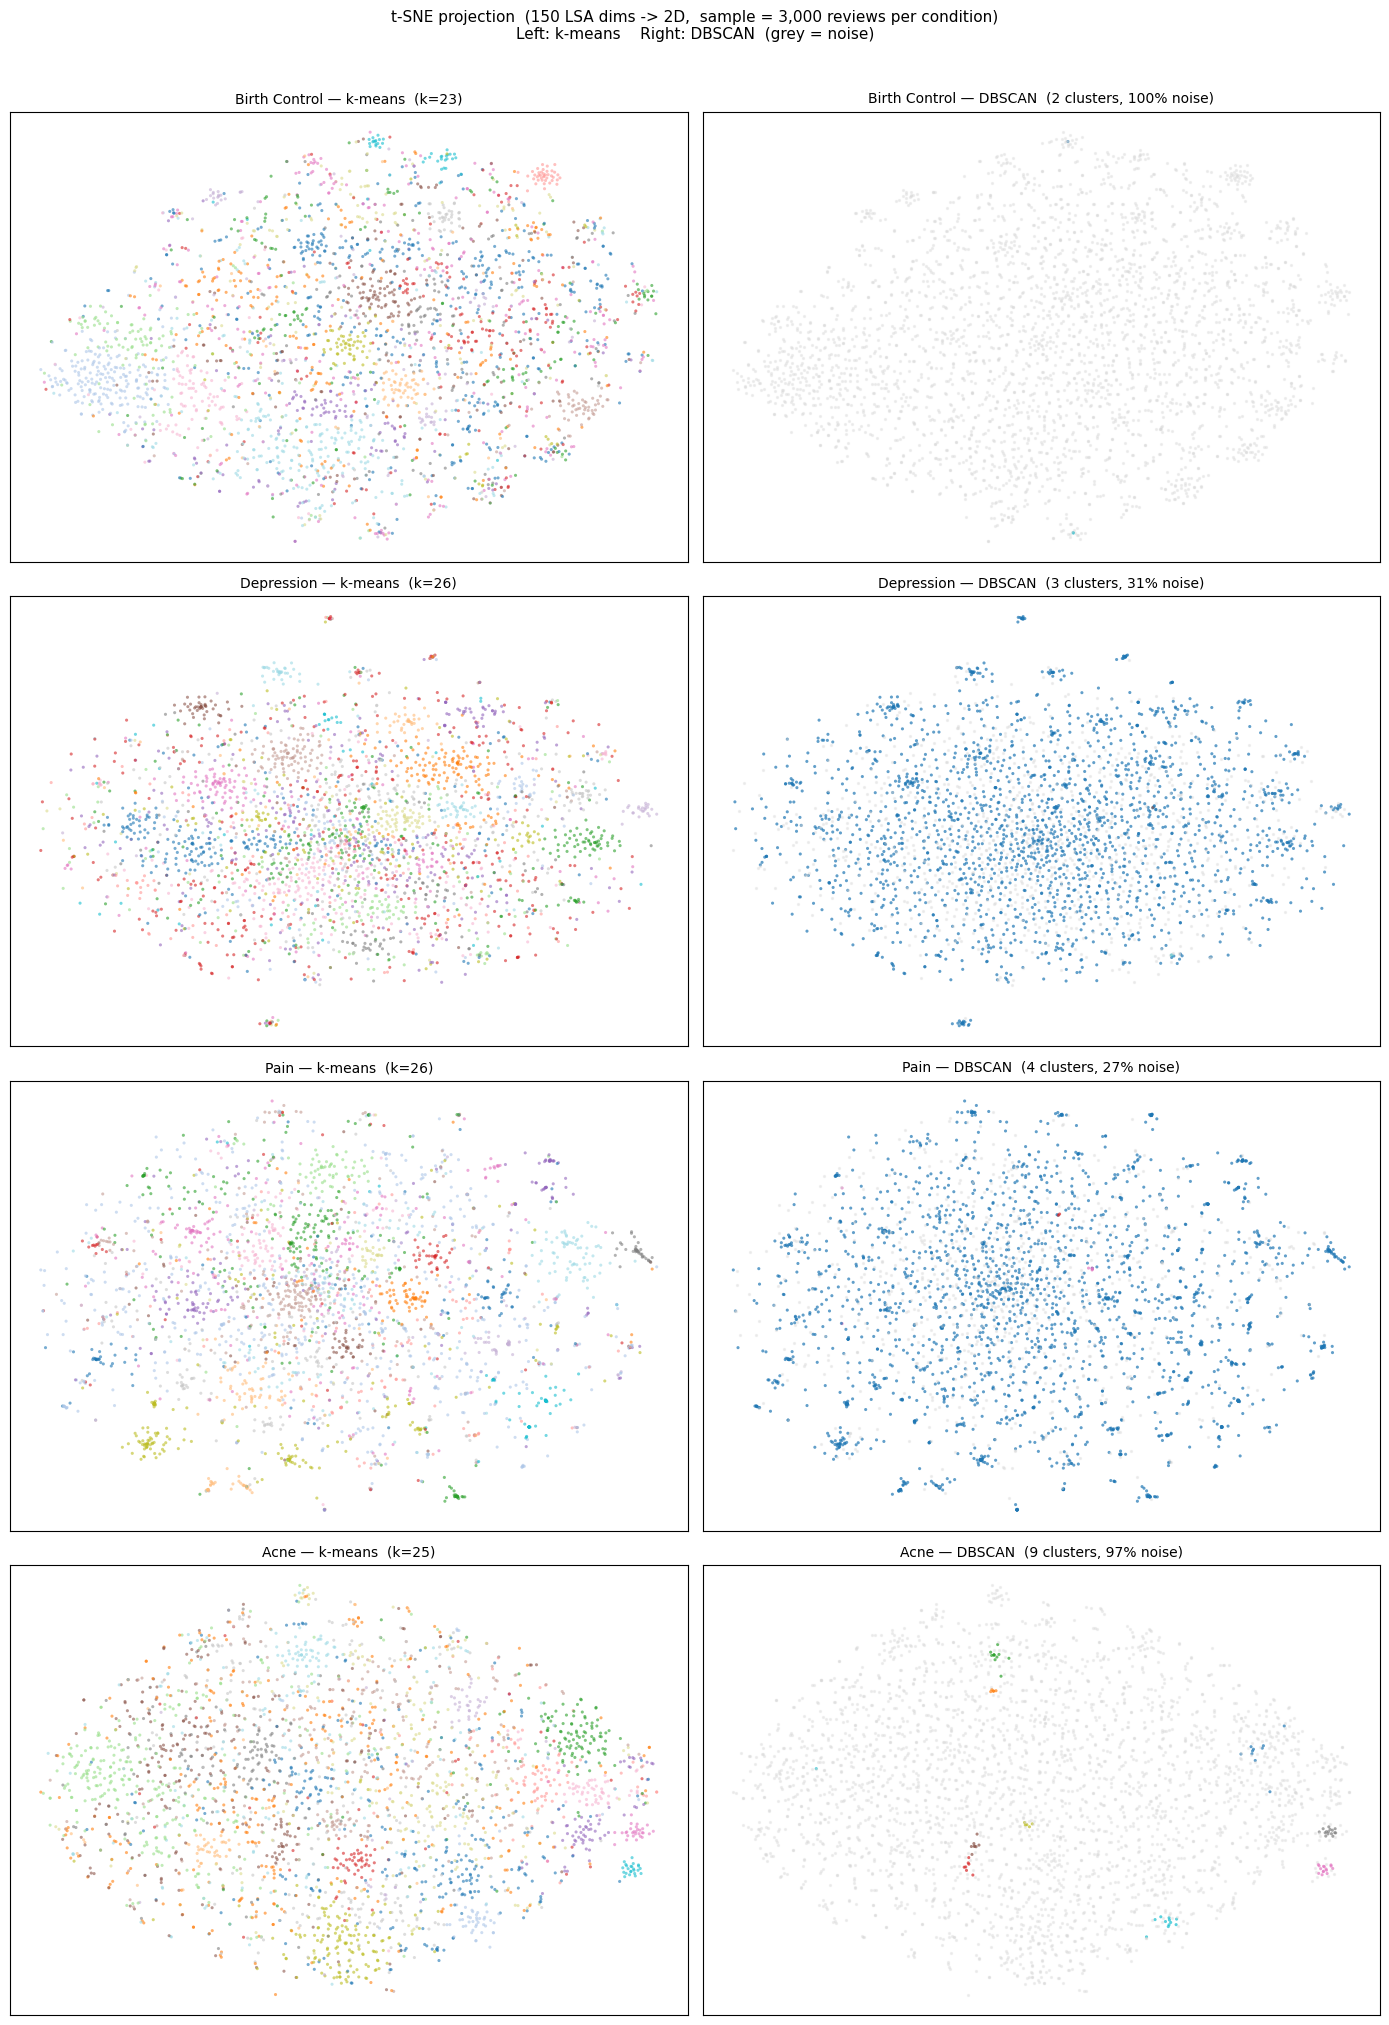

In [22]:
from sklearn.manifold import TSNE

TSNE_MAX_POINTS = 3_000
TSNE_PERPLEXITY = 30
TSNE_N_ITER     = 1_000

fig, axes = plt.subplots(len(CONDITIONS), 2, figsize=(14, 5 * len(CONDITIONS)))

for row_i, cond in enumerate(CONDITIONS):
    X      = svd_matrices[cond]
    km_lbs = kmeans_labels[cond]
    db_lbs = dbscan_labels[cond]
    n      = len(X)

    rng = np.random.RandomState(RANDOM_STATE)
    idx = rng.choice(n, size=min(TSNE_MAX_POINTS, n), replace=False)
    X_sub  = X[idx]
    km_sub = km_lbs[idx]
    db_sub = db_lbs[idx]

    print(f'{cond}: t-SNE on {len(idx):,} points ...', flush=True)
    t0   = time.perf_counter()
    proj = TSNE(n_components=2, perplexity=TSNE_PERPLEXITY, n_iter=TSNE_N_ITER,
                random_state=RANDOM_STATE).fit_transform(X_sub)
    print(f'  done in {time.perf_counter() - t0:.1f}s')

    # K-means left
    ax_km = axes[row_i, 0]
    ax_km.scatter(proj[:, 0], proj[:, 1],
                  c=km_sub, cmap='tab20', s=5, alpha=0.6, linewidths=0)
    ax_km.set_title(f'{cond} — k-means  (k={k_best[cond]})', fontsize=10)
    ax_km.set_xticks([]); ax_km.set_yticks([])

    # DBSCAN right — noise in grey
    ax_db = axes[row_i, 1]
    noise_mask = db_sub == -1
    core_mask  = ~noise_mask
    if core_mask.any():
        ax_db.scatter(proj[core_mask, 0], proj[core_mask, 1],
                      c=db_sub[core_mask], cmap='tab10', s=5, alpha=0.7, linewidths=0)
    if noise_mask.any():
        ax_db.scatter(proj[noise_mask, 0], proj[noise_mask, 1],
                      c='lightgrey', s=2, alpha=0.3)
    n_clust     = int(db_sub[core_mask].max() + 1) if core_mask.any() else 0
    n_noise_pct = noise_mask.mean()
    ax_db.set_title(
        f'{cond} — DBSCAN  ({n_clust} clusters, {n_noise_pct:.0%} noise)',
        fontsize=10)
    ax_db.set_xticks([]); ax_db.set_yticks([])

fig.suptitle(
    't-SNE projection  (150 LSA dims -> 2D,  sample = 3,000 reviews per condition)\n'
    'Left: k-means    Right: DBSCAN  (grey = noise)',
    y=1.01, fontsize=11)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'tsne_clusters.png', dpi=150, bbox_inches='tight')
plt.show()


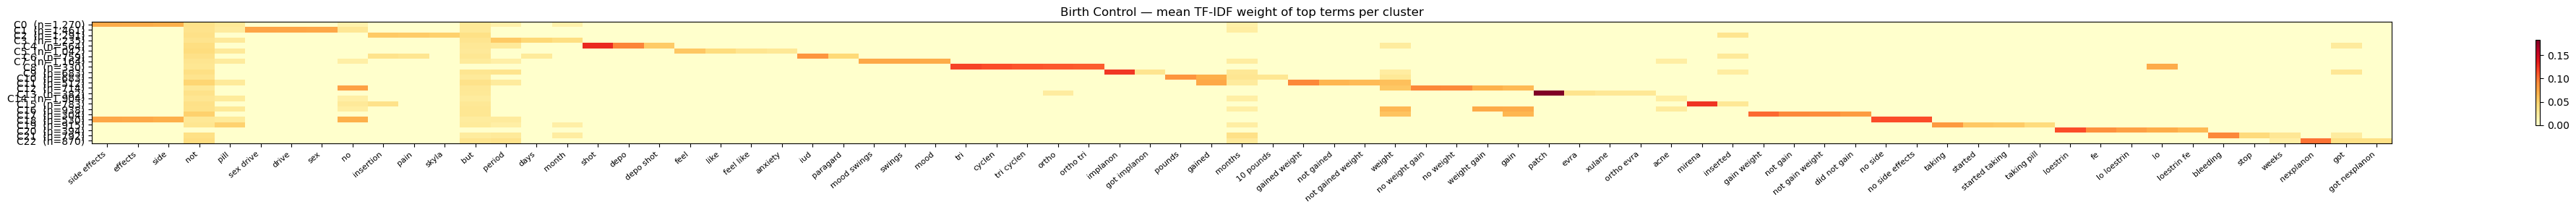

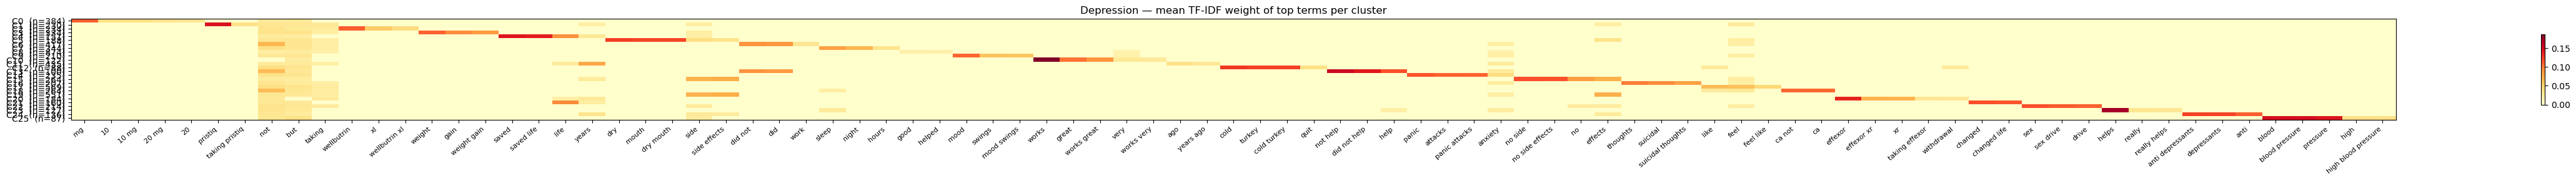

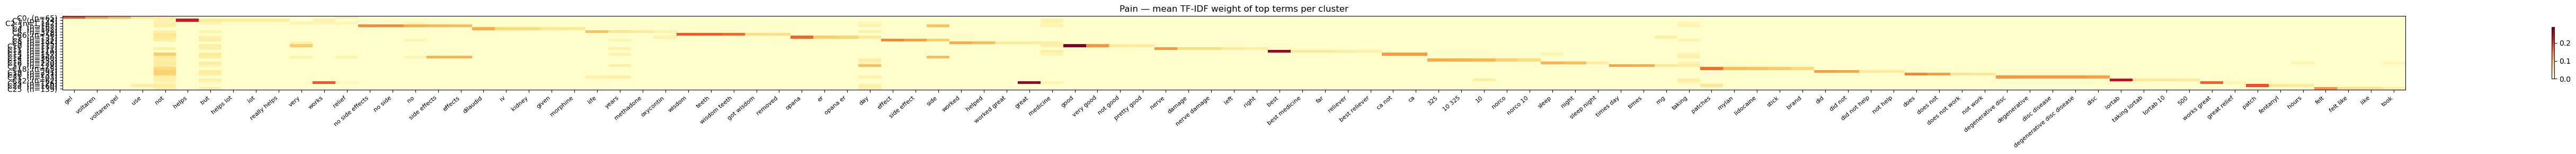

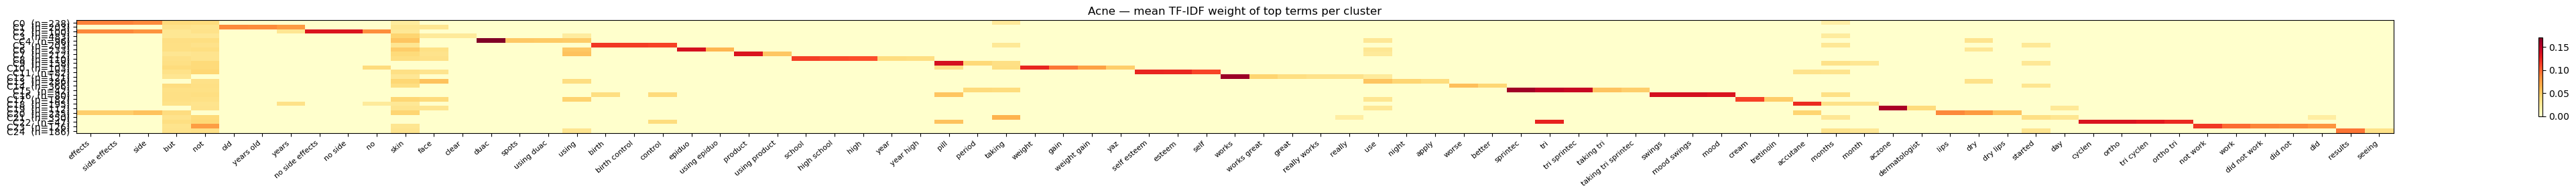

In [23]:
# Heatmap: mean TF-IDF weight of the top-5 terms per cluster, per condition
for cond in CONDITIONS:
    # collect top-5 terms across all clusters
    all_terms = []
    for cid, info in profiles[cond].items():
        all_terms += [t for t, _ in info['top_terms'][:5]]
    all_terms = list(dict.fromkeys(all_terms))   # deduplicate, preserve order

    heatmap_data = np.zeros((len(profiles[cond]), len(all_terms)))
    cluster_ids  = sorted(profiles[cond])
    for row_i, cid in enumerate(cluster_ids):
        term_weights = dict(profiles[cond][cid]['top_terms'])
        for col_j, term in enumerate(all_terms):
            heatmap_data[row_i, col_j] = term_weights.get(term, 0.0)

    fig, ax = plt.subplots(figsize=(max(8, len(all_terms) * 0.55), 3))
    im = ax.imshow(heatmap_data, aspect='auto', cmap='YlOrRd')
    ax.set_xticks(range(len(all_terms)))
    ax.set_xticklabels(all_terms, rotation=40, ha='right', fontsize=8)
    ax.set_yticks(range(len(cluster_ids)))
    ax.set_yticklabels([f'C{c}  (n={profiles[cond][c]["size"]:,})' for c in cluster_ids])
    ax.set_title(f'{cond} — mean TF-IDF weight of top terms per cluster')
    plt.colorbar(im, ax=ax, shrink=0.7)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f'cluster_terms_{cond.lower().replace(" ", "_")}.png',
                dpi=150, bbox_inches='tight')
    plt.show()

### B7 · Results — Cluster interpretation

**Limitation: brand clusters vs experience clusters.**  
A significant fraction of clusters are organised around *brand or delivery-method vocabulary* rather than *patient experience types*. This is an inherent consequence of TF-IDF weighting: brand names (Mirena, Loestrin, Nexplanon, Implanon, Depo, Effexor, Zoloft, Epiduo, Accutane…) are highly distinctive tokens with large TF-IDF weights that dominate the centroid of any cluster where they appear. The result is that k-means partly performs brand disambiguation rather than pure experience clustering.

| Condition | Brand/delivery-method clusters | Experience clusters |
|---|---|---|
| Birth Control | Mirena, Skyla, Implanon, Nexplanon, Depo, NuvaRing, Loestrin, patch, Ortho Tri-Cyclen | Mood swings, weight gain, sex drive, bleeding/spotting, anxiety as side effect, insertion pain |
| Depression | Lexapro, Zoloft, Effexor XR, Wellbutrin XL, Cymbalta, Pristiq | "Saved my life", weight gain, sex drive, sleep/insomnia, panic attacks, dry mouth, withdrawal, dosage discussion |
| Pain | Opana, Tramadol, fentanyl patch, Dilaudid/Toradol, Mylan lidocaine | Chronic relief, stomach upset, "takes it away", quality of life, degenerative disc |
| Acne | Accutane, Aczone, Epiduo, benzoyl peroxide, Duac | Oily skin, purging (gets worse first), birth-control-induced acne, cystic acne, cleared skin, high school/teen |

**Implication for the research question:**  
The research question asks whether reviews can be grouped into *common experience types* (weight gain, mood swings, etc.). The answer is yes — such clusters do emerge clearly — but they coexist with brand clusters that reflect *what drug patients took* rather than *what they experienced*. For a pure experience-type analysis, brand names could be added to the stop-word list; this would collapse the brand clusters and force k-means to find only experience-based structure. The current approach preserves both, which is useful for the drug-family analysis in Role E.

---

The top terms are now clean content words throughout — no stop-word artifacts pollute the signal.

**Birth Control** — clusters split on two axes: *delivery method / brand* and *side-effect type*. The anxiety/depression side-effect cluster carries the lowest mean rating across all conditions; the IUD insertion clusters carry the highest.

**Depression** — the "saved my life" cluster (highest-rated cluster across all conditions) coexists with a withdrawal symptoms cluster (lowest-rated). Brand clusters (Lexapro, Zoloft, Wellbutrin…) reflect that patients often name their specific antidepressant.

**Pain** — clusters split on sentiment strength ("works great", "takes it away", "quality of life") and drug type (Opana, fentanyl patch, Dilaudid for hospital-administered opioids).

**Acne** — the purging cluster ("worse gets better") and the hormonal/pill-weight cluster are the lowest-rated; Accutane and "it worked" clusters are the highest.

## B8 · Does cluster membership predict rating?

**Kruskal-Wallis H-test**: non-parametric one-way test of whether ratings differ across clusters (null: all clusters have the same rating distribution).

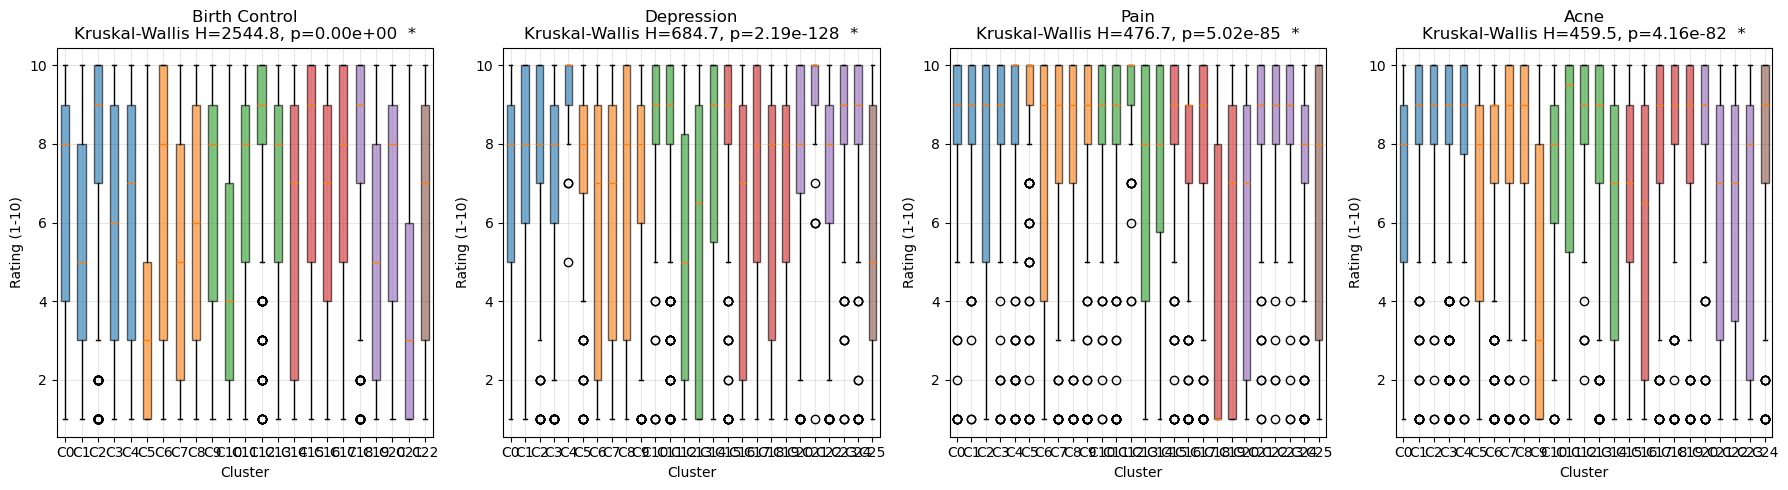

Birth Control         H=2544.83  p=0.00e+00  -> significant
Depression            H=684.72  p=2.19e-128  -> significant
Pain                  H=476.74  p=5.02e-85  -> significant
Acne                  H=459.48  p=4.16e-82  -> significant


In [24]:
rating_tests = {}
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(18, 5))

for ax, cond in zip(axes, CONDITIONS):
    subset  = scoped[scoped['condition_name'] == cond].reset_index(drop=True)
    labels  = kmeans_labels[cond]
    cluster_ids = sorted(set(labels))

    groups = [subset.loc[labels == cid, 'rating'].values for cid in cluster_ids]
    H, p   = stats.kruskal(*groups)

    rating_tests[cond] = {
        'H': round(float(H), 2),
        'p': float(p),
        'significant': bool(p < 0.05),
    }

    bp = ax.boxplot(groups, labels=[f'C{c}' for c in cluster_ids], patch_artist=True)
    colors_bp = plt.cm.tab10(np.linspace(0, 0.5, len(cluster_ids)))
    for patch, col in zip(bp['boxes'], colors_bp):
        patch.set_facecolor(col)
        patch.set_alpha(0.6)
    sig_str = f'p={p:.2e}  {"*" if p < 0.05 else "n.s."}'
    ax.set_title(f'{cond}\nKruskal-Wallis H={H:.1f}, {sig_str}')
    ax.set_xlabel('Cluster')
    ax.set_ylabel('Rating (1-10)')
    ax.grid(alpha=0.3)

run_stats['rating_vs_cluster'] = rating_tests
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'rating_by_cluster.png', dpi=150, bbox_inches='tight')
plt.show()

for cond, res in rating_tests.items():
    sig = 'significant' if res['significant'] else 'NOT significant'
    print(f'{cond:<20s}  H={res["H"]}  p={res["p"]:.2e}  -> {sig}')

### B8 · Results — Rating prediction

The Kruskal-Wallis test is significant for **all four conditions** (p ≈ 0), confirming that cluster membership predicts rating.

| Condition | H statistic | Interpretation |
|---|---|---|
| Birth Control | 2,545 | Very strong — clusters capture distinct experience types with large rating gaps |
| Depression | 685 | Strong — positive vs negative experience clusters are well separated |
| Pain | 477 | Strong — relief vs no-relief clusters drive the signal |
| Acne | 459 | Strong — Accutane users vs hormonal treatments show different satisfaction levels |

H statistics are strong across all conditions. The negation handling (expanded contractions) ensures that "did not work", "no side effects", and "not gain weight" are captured as meaningful cluster signals.


## B9 · Save outputs

| File | Used by |
|---|---|
| `cluster_assignments.parquet` | Everyone: join to any table on `review_id` |
| `cluster_profiles.csv` | Report: top terms and mean rating per cluster |
| `figures/` | Report: scatter, DB sweep, heatmaps |
| `role_b_run_stats.json` | Report: all numbers |

In [25]:
# ── cluster_assignments.parquet ──────────────────────────────────────────────
assignment_rows = []
for cond in CONDITIONS:
    subset    = scoped[scoped['condition_name'] == cond].reset_index(drop=True)
    km_labels = kmeans_labels[cond]
    db_labels = dbscan_labels[cond]
    for i in range(len(subset)):
        assignment_rows.append({
            'review_id':      subset.at[i, 'review_id'],
            'condition_name': cond,
            'drug_family':    subset.at[i, 'drug_family'],
            'rating':         int(subset.at[i, 'rating']),
            'kmeans_cluster': int(km_labels[i]),
            'dbscan_cluster': int(db_labels[i]),
        })

assignments_df = pd.DataFrame(assignment_rows)
assignments_df.to_parquet(OUTPUT_DIR / 'cluster_assignments.parquet', index=False)
print(f'Saved cluster_assignments.parquet  ({len(assignments_df):,} rows)')

# ── cluster_profiles.csv ──────────────────────────────────────────────────────
profile_rows = []
for cond in CONDITIONS:
    for cid, info in profiles[cond].items():
        profile_rows.append({
            'condition':   cond,
            'cluster':     cid,
            'size':        info['size'],
            'mean_rating': info['mean_rating'],
            'std_rating':  info['std_rating'],
            'top_5_terms': ' | '.join(t for t, _ in info['top_terms'][:5]),
            'top_10_terms': ' | '.join(t for t, _ in info['top_terms'][:10]),
        })
pd.DataFrame(profile_rows).to_csv(OUTPUT_DIR / 'cluster_profiles.csv', index=False)
print(f'Saved cluster_profiles.csv  ({len(profile_rows)} rows)')

# ── run_stats.json ────────────────────────────────────────────────────────────
run_stats['k_best']             = k_best
run_stats['dbscan_best_params'] = dbscan_best_params
run_stats['profiles'] = {
    cond: {
        str(cid): {k: v for k, v in info.items() if k != 'sample_reviews'}
        for cid, info in cond_profiles.items()
    }
    for cond, cond_profiles in profiles.items()
}
run_stats['runtime_minutes'] = round((time.perf_counter() - NOTEBOOK_STARTED) / 60, 1)


def _json_safe(v):
    if hasattr(v, 'item'):   # numpy scalar
        return v.item()
    return str(v)


(OUTPUT_DIR / 'role_b_run_stats.json').write_text(
    json.dumps(run_stats, indent=2, default=_json_safe), encoding='utf-8'
)
print(f'Saved role_b_run_stats.json')
print(f'Total elapsed: {run_stats["runtime_minutes"]:.1f} min')
print(f'\nAll outputs in {OUTPUT_DIR}/')

Saved cluster_assignments.parquet  (36,365 rows)
Saved cluster_profiles.csv  (100 rows)
Saved role_b_run_stats.json
Total elapsed: 59.5 min

All outputs in outputs/


## B10 · Review browser

Utility to read actual review text — by condition, by cluster, or by keyword search.

In [26]:
def show_reviews(condition, cluster=None, keyword=None, n=5, random_state=42):
    """
    
    Print sample reviews.

    Parameters
    ----------
    condition   : str   one of CONDITIONS
    cluster     : int   k-means cluster id (None = any cluster)
    keyword     : str   filter to reviews containing this word (case-insensitive)
    n           : int   number of reviews to show
    """
    subset = scoped[scoped['condition_name'] == condition].reset_index(drop=True)
    labels = kmeans_labels[condition]
    subset = subset.assign(cluster=labels)

    if cluster is not None:
        subset = subset[subset['cluster'] == cluster]
    if keyword:
        subset = subset[subset['review_text_clean'].str.contains(keyword, case=False, na=False)]

    sample = subset.sample(min(n, len(subset)), random_state=random_state)

    top_terms = ''
    if cluster is not None and cluster in profiles.get(condition, {}):
        terms = ', '.join(t for t, _ in profiles[condition][cluster]['top_terms'][:5])
        rating = profiles[condition][cluster]['mean_rating']
        top_terms = f'  |  top terms: {terms}  |  mean rating: {rating}'

    print(f'Condition: {condition}  |  cluster: {cluster}  |  keyword: {keyword!r}{top_terms}')
    print(f'Showing {len(sample)} of {len(subset)} matching reviews')
    print('=' * 80)
    for _, row in sample.iterrows():
        print(f'[C{row["cluster"]}  rating={row["rating"]}]')
        print(row['review_text_clean'])
        print('-' * 80)


# ── Examples — change these to explore ───────────────────────────────────────

# All conditions and their cluster counts:
for cond in CONDITIONS:
    n_c = len(set(kmeans_labels[cond]))
    print(f'{cond:<20s}  {n_c} clusters  (C0 ... C{n_c-1})')

print()
# Show 3 reviews from the Depression 'saved my life' cluster
show_reviews('Depression', cluster=9, n=3)


Birth Control         23 clusters  (C0 ... C22)
Depression            26 clusters  (C0 ... C25)
Pain                  26 clusters  (C0 ... C25)
Acne                  25 clusters  (C0 ... C24)

Condition: Depression  |  cluster: 9  |  keyword: None  |  top terms: mood, swings, mood swings, but, not  |  mean rating: 7.25
Showing 3 of 210 matching reviews
[C9  rating=6]
Improves my mood, less stressed but nauseous and sweaty.
--------------------------------------------------------------------------------
[C9  rating=10]
I'm 47 and have had classic depression and anxiety since my early 20's. Been on citalopram, fluoxetine, marititizapam and now sertraline. Also have dizapam as a back up. This year has been extremely difficult no major incidents but my depression was changing from day to day. No ups but plenty of downs. Finally couldnt cope and pressured the dr to give me something for mood swings in addition to my sertraline. I can say I have felt the best I ever had in 20 years!!!! My mo